# Predicción de abandono de clientes en una empresa de telecomunicaciones
## Proyecto Final Integrador — Diplomado en Ciencia de Datos y Análisis Avanzado (UTN.BA)

**Autor:** Nicolás Alejo Lombardia · **Fecha:** 26 de octubre de 2026

El objetivo es ordenar la cartera por riesgo de baja para que el área de Retención concentre
sus contactos en los clientes que más probablemente se vayan. Todos los números del informe
salen de este notebook y se guardan en `results/`.

| Etapa CRISP-DM | Sección | Salidas en `results/` |
|---|---|---|
| Comprensión del negocio | 1 | — |
| Comprensión de los datos | 2 | `eda_calidad.csv`, `eda_tasas.csv`, `fig_eda.png` |
| Preparación | 3 | — |
| Modelado | 4 | `busqueda_hiperparametros.csv`, `cv_5folds.csv`, `desbalance.csv` |
| Evaluación | 5 | `model_metrics.csv`, `meta_ex_ante.csv`, `lift_deciles.csv`, `bootstrap_holdout.csv`, `fig_pr_ganancia.png` |
| Interpretación | 6 | `coeficientes.csv`, `fig_coeficientes.png` |
| Ética y auditoría | 7 | `auditoria_grupos.csv`, `ablaciones.csv` |
| Impacto en el negocio | 8 | `escenario_economico.csv`, `fig_escenarios.png` |
| Despliegue (scoring) | 9 | `predicciones_test.csv` |

**Cómo ejecutar:** ubicar `train.csv` y `test.csv` en `data/` (ver `data/README.md`),
instalar `requirements.txt` y ejecutar todas las celdas. En Colab, si faltan los CSV, la primera
celda de datos abre un diálogo para subirlos. Corre en unos 4 minutos en una CPU común.

In [1]:
import os, math, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, accuracy_score, precision_recall_curve, make_scorer)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
DATA, RES = 'data', 'results'
os.makedirs(RES, exist_ok=True)

# Gráficos en blanco y negro: las series se distinguen por tono de gris y tipo de línea
C_LR, C_RF, C_XGB, C_REF = '#000000', '#555555', '#9a9a9a', '#777777'
LS = {'Regresión Logística ampliada': '-', 'Random Forest': '--', 'XGBoost': ':'}
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
                     'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'],
                     'text.color': 'black', 'axes.labelcolor': 'black', 'xtick.color': 'black', 'ytick.color': 'black',
                     'axes.edgecolor': 'black', 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.titleweight': 'bold'})

def pct(x, dec=0):
    # Porcentaje con coma decimal y espacio, como en el informe: 26,5 %
    return f'{x * 100:.{dec}f} %'.replace('.', ',')

def num(x, dec=3):
    return f'{x:.{dec}f}'.replace('.', ',')

FMT_PCT = plt.FuncFormatter(lambda x, _: pct(x))

def guardar(df, nombre):
    df.to_csv(f'{RES}/{nombre}', index=False, float_format='%.4f')
    return df

def recall_at_k(y, score, k=0.20):
    # Proporción de las bajas reales que cae dentro del k% de clientes con mayor score
    y = np.asarray(y); n = math.ceil(k * len(y))
    top = np.argsort(-np.asarray(score), kind='stable')[:n]
    return y[top].sum() / y.sum()

def precision_at_k(y, score, k=0.20):
    y = np.asarray(y); n = math.ceil(k * len(y))
    top = np.argsort(-np.asarray(score), kind='stable')[:n]
    return y[top].mean()

## 1. Comprensión del negocio

**Problema.** Uno de cada cuatro clientes se da de baja. Hoy la regla de Retención es llamar a
todos los que pagan mes a mes, que son más de la mitad de la base. El modelo debe ordenar a los
clientes por riesgo para que la misma capacidad de contacto encuentre más bajas.

**KPI del modelo (medible con estos datos).** Proporción de las bajas reales que quedan dentro
del 20 % de clientes con mayor riesgo (*captura en el top 20 %*), junto con la precisión de ese
grupo. Se reportan además ROC AUC, PR-AUC, Recall y Precision.

**KPI de negocio (no medible con estos datos).** Ingreso retenido y reducción de la tasa de bajas
en los clientes contactados. Requiere una campaña con grupo de control; acá solo se estima como
escenario con supuestos explícitos (sección 8).

**Regla de selección fijada antes de mirar el holdout.** Gana el modelo con mayor PR-AUC promedio
en validación cruzada de 5 folds. Si la ventaja sobre la Regresión Logística es menor que el
desvío entre folds del mejor modelo, se elige la Regresión Logística por ser más simple e
interpretable.

In [2]:
# En Colab, si los CSV no están en data/, se piden por diálogo de carga
if not os.path.exists(f'{DATA}/train.csv'):
    try:
        from google.colab import files
        os.makedirs(DATA, exist_ok=True)
        print('Subí train.csv y test.csv (ver data/README.md)')
        for nombre, contenido in files.upload().items():
            open(f'{DATA}/{nombre}', 'wb').write(contenido)
    except ImportError:
        raise FileNotFoundError('Faltan data/train.csv y data/test.csv: ver data/README.md')

train = pd.read_csv(f'{DATA}/train.csv')
test = pd.read_csv(f'{DATA}/test.csv')
print('train:', train.shape, '| test:', test.shape)
print('Tasa de bajas en train: {:.1%}'.format((train['Churn'] == 'Yes').mean()))

train: (5634, 21) | test: (1409, 20)
Tasa de bajas en train: 26.5%


## 2. Comprensión de los datos

### 2.1 Calidad

In [3]:
calidad = []
calidad.append(('Celdas vacías en train', int(train.isna().sum().sum())))
calidad.append(('Celdas vacías en test', int(test.isna().sum().sum())))
calidad.append(('Filas duplicadas (sin ID)', int(train.drop(columns='customerID').duplicated().sum())))
calidad.append(('IDs repetidos entre train y test', len(set(train.customerID) & set(test.customerID))))

t0 = train[train.tenure == 0]
calidad.append(('Clientes con antigüedad 0 (train)', len(t0)))
calidad.append(('  de ellos con TotalCharges = 1397,475', int((t0.TotalCharges.round(3) == 1397.475).sum())))
calidad.append(('Mediana de TotalCharges (train)', round(train.TotalCharges.median(), 3)))
calidad.append(('Clientes con antigüedad 0 (test)', int((test.tenure == 0).sum())))

esperado = train.tenure * train.MonthlyCharges
calidad.append(('Correlación TotalCharges vs tenure × MonthlyCharges', round(np.corrcoef(esperado, train.TotalCharges)[0, 1], 4)))
calidad.append(('Correlación TotalCharges vs tenure', round(train[['TotalCharges', 'tenure']].corr().iloc[0, 1], 4)))

calidad = guardar(pd.DataFrame(calidad, columns=['Chequeo', 'Valor']), 'eda_calidad.csv')
calidad

,Chequeo,Valor
0,Celdas vacías en train,0.0000
1,Celdas vacías en test,0.0000
2,Filas duplicadas (sin ID),15.0000
3,IDs repetidos entre train y test,0.0000
4,Clientes con antigüedad 0 (train),8.0000
5,"de ellos con TotalCharges = 1397,475",8.0000
6,Mediana de TotalCharges (train),1397.4750
7,Clientes con antigüedad 0 (test),3.0000
8,Correlación TotalCharges vs tenure × MonthlyCh...,0.9993
9,Correlación TotalCharges vs tenure,0.8291


**Hallazgo de calidad.** En el dataset original, los clientes con antigüedad 0 tienen
`TotalCharges` en blanco porque todavía no pagaron nada. Acá esas celdas aparecen completadas con
exactamente la mediana de la columna (1397,475 USD). Es una imputación que no tiene sentido de
negocio: un cliente recién llegado figura como si hubiera pagado casi dos años. Se corrige en la
preparación asignando 0. Además, `TotalCharges` es casi el producto de antigüedad y cargo
mensual, así que aporta poca información nueva.

### 2.2 Análisis exploratorio

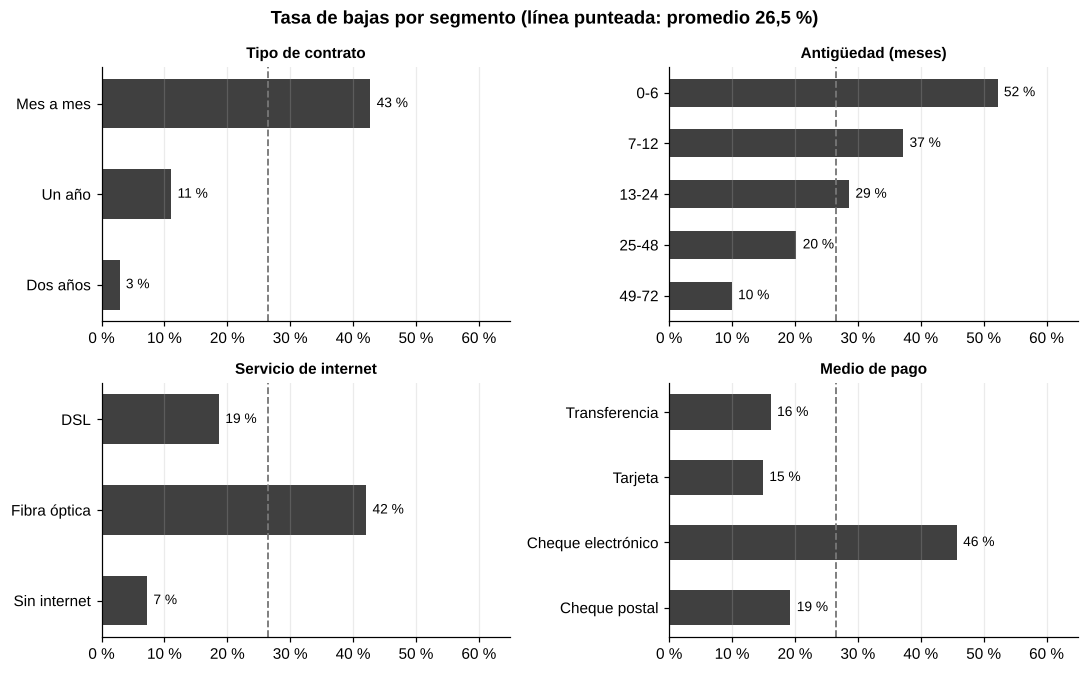

Mes a mes: 55.1% de la base, tasa de baja 42.7%, concentra 88.7% de las bajas


In [4]:
y_all = (train.Churn == 'Yes').astype(int)
base_rate = y_all.mean()
eda = train.assign(baja=y_all,
                   antiguedad=pd.cut(train.tenure, [-1, 6, 12, 24, 48, 72],
                                     labels=['0-6', '7-12', '13-24', '25-48', '49-72']))
filas = []
for var in ['Contract', 'antiguedad', 'InternetService', 'PaymentMethod', 'TechSupport',
            'OnlineSecurity', 'PaperlessBilling', 'SeniorCitizen']:
    g = eda.groupby(var, observed=True).baja.agg(['size', 'mean']).reset_index()
    for _, r in g.iterrows():
        filas.append({'variable': var, 'categoria': str(r[var]), 'clientes': int(r['size']),
                      'pct_base': r['size'] / len(eda), 'tasa_baja': r['mean']})
tasas = guardar(pd.DataFrame(filas), 'eda_tasas.csv')

etiquetas = {'Contract': 'Tipo de contrato', 'antiguedad': 'Antigüedad (meses)',
             'InternetService': 'Servicio de internet', 'PaymentMethod': 'Medio de pago'}
traduc = {'Month-to-month': 'Mes a mes', 'One year': 'Un año', 'Two year': 'Dos años',
          'Fiber optic': 'Fibra óptica', 'No': 'Sin internet', 'DSL': 'DSL',
          'Electronic check': 'Cheque electrónico', 'Mailed check': 'Cheque postal',
          'Bank transfer (automatic)': 'Transferencia', 'Credit card (automatic)': 'Tarjeta'}
fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
for ax, (var, titulo) in zip(axes.ravel(), etiquetas.items()):
    d = tasas[tasas.variable == var]
    labels = [traduc.get(c, c) for c in d.categoria]
    ax.barh(labels, d.tasa_baja, color='#404040', height=.55)
    ax.axvline(base_rate, color=C_REF, ls='--', lw=1.2)
    for i, v in enumerate(d.tasa_baja):
        ax.text(v + .01, i, pct(v), va='center', fontsize=9)
    ax.set_title(titulo, fontsize=10); ax.set_xlim(0, .65); ax.invert_yaxis()
    ax.xaxis.set_major_formatter(FMT_PCT); ax.grid(axis='y', alpha=0)
fig.suptitle(f'Tasa de bajas por segmento (línea punteada: promedio {pct(base_rate, 1)})', fontweight='bold')
fig.tight_layout(); fig.savefig(f'{RES}/fig_eda.png'); plt.show()

mm = tasas[(tasas.variable == 'Contract') & (tasas.categoria == 'Month-to-month')].iloc[0]
share_bajas_mm = (eda[eda.Contract == 'Month-to-month'].baja.sum() / eda.baja.sum())
print(f'Mes a mes: {mm.pct_base:.1%} de la base, tasa de baja {mm.tasa_baja:.1%}, concentra {share_bajas_mm:.1%} de las bajas')

Las tres hipótesis de la pre-entrega se confirman en el exploratorio: el contrato mes a mes
concentra casi todas las bajas, el riesgo se acumula en los primeros meses, y pesan la fibra
óptica (factura alta), la falta de soporte y el pago con cheque electrónico.

## 3. Preparación de los datos

- Se elimina `customerID` y se codifica `Churn` como 0/1.
- Se corrige `TotalCharges = 0` para los clientes con antigüedad 0 (ver 2.1).
- Variables nuevas: `n_servicios` (cantidad de servicios adicionales contratados),
  `cargo_promedio` (lo pagado en promedio por mes de antigüedad) y `dif_cargo`
  (cargo actual menos el promedio histórico; un valor alto sugiere un aumento reciente).
- Desbalance: se prueba la ponderación de clases en la sección 4.1. El corte se decide por
  capacidad de contacto, no por el umbral 0,5.
- La división es la misma de los trabajos anteriores (80/20 estratificada, semilla 42), así que la
  Regresión Logística base reproduce el ROC AUC 0,848 ya reportado.
- Todo el preprocesamiento vive dentro de un `Pipeline` que se ajusta solo con datos de
  entrenamiento en cada fold.

In [5]:
SERVICIOS = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

def preparar(df):
    d = df.copy()
    d.loc[d.tenure == 0, 'TotalCharges'] = 0.0
    d['n_servicios'] = (d[SERVICIOS] == 'Yes').sum(axis=1) + (d.MultipleLines == 'Yes').astype(int)
    d['cargo_promedio'] = np.where(d.tenure > 0, d.TotalCharges / d.tenure.clip(lower=1), d.MonthlyCharges)
    d['dif_cargo'] = d.MonthlyCharges - d.cargo_promedio
    return d

df = preparar(train)
y = (df.Churn == 'Yes').astype(int).values
X = df.drop(columns=['customerID', 'Churn'])

NUM_BASE = ['tenure', 'MonthlyCharges', 'TotalCharges']
NUM_NUEVAS = ['n_servicios', 'cargo_promedio', 'dif_cargo']
CAT = [c for c in X.columns if c not in NUM_BASE + NUM_NUEVAS + ['SeniorCitizen']] + ['SeniorCitizen']

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print('Entrenamiento:', X_tr.shape, '| Holdout:', X_te.shape, '| bajas en holdout:', y_te.sum())

def preproc(num, cat, escalar):
    return ColumnTransformer([
        ('num', StandardScaler() if escalar else 'passthrough', num),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat)])

Entrenamiento: (4507, 22) | Holdout: (1127, 22) | bajas en holdout: 299


## 4. Modelado

Se comparan cuatro configuraciones:

- **Regresión Logística base**: mismas variables y preprocesamiento que la pre-entrega (baseline).
- **Regresión Logística ampliada**: con la corrección de calidad y las variables nuevas.
- **Random Forest** y **XGBoost**: ensambles de árboles, con hiperparámetros buscados por
  validación cruzada (25 combinaciones al azar, optimizando PR-AUC).

No se incluyen redes neuronales: en el TP del Módulo 8, sobre este mismo split, la mejor red
(Dropout + EarlyStopping) obtuvo ROC AUC 0,841 de media en cinco semillas, por debajo del 0,848
de la Regresión Logística, con cientos de veces más cómputo.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
NUM_ALL = NUM_BASE + NUM_NUEVAS

modelos = {
    'Regresión Logística base': Pipeline([('prep', preproc(NUM_BASE, CAT, True)),
                                          ('clf', LogisticRegression(max_iter=2000, random_state=SEED))]),
    'Regresión Logística ampliada': Pipeline([('prep', preproc(NUM_ALL, CAT, True)),
                                              ('clf', LogisticRegression(max_iter=2000, random_state=SEED))]),
}

busquedas = {
    'Random Forest': (RandomForestClassifier(random_state=SEED, n_jobs=-1),
                      {'clf__n_estimators': [300, 500, 800], 'clf__max_depth': [4, 6, 8, 10, None],
                       'clf__min_samples_leaf': [1, 5, 10, 20, 40], 'clf__max_features': ['sqrt', 0.3, 0.5]}),
    'XGBoost': (XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='logloss', tree_method='hist'),
                {'clf__n_estimators': [200, 400, 600], 'clf__max_depth': [2, 3, 4, 5],
                 'clf__learning_rate': [0.01, 0.03, 0.05, 0.1], 'clf__subsample': [0.7, 0.85, 1.0],
                 'clf__colsample_bytree': [0.6, 0.8, 1.0], 'clf__min_child_weight': [1, 5, 10]}),
}
filas_busqueda = []
for nombre, (est, grid) in busquedas.items():
    pipe = Pipeline([('prep', preproc(NUM_ALL, CAT, False)), ('clf', est)])
    rs = RandomizedSearchCV(pipe, grid, n_iter=25, scoring='average_precision', cv=cv,
                            random_state=SEED, n_jobs=-1)
    rs.fit(X_tr, y_tr)
    modelos[nombre] = rs.best_estimator_
    params = {k.replace('clf__', ''): v for k, v in rs.best_params_.items()}
    filas_busqueda.append({'modelo': nombre, 'pr_auc_cv_busqueda': rs.best_score_, 'mejores_parametros': json.dumps(params)})
    print(f'{nombre}: {params} | PR-AUC {rs.best_score_:.4f}')
guardar(pd.DataFrame(filas_busqueda), 'busqueda_hiperparametros.csv');

Random Forest: {'n_estimators': 800, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 8} | PR-AUC 0.6621


XGBoost: {'subsample': 1.0, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 2, 'learning_rate': 0.03, 'colsample_bytree': 1.0} | PR-AUC 0.6654


In [7]:
# Evaluación con folds distintos a los de la búsqueda, para no reutilizar la misma partición
cv_eval = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision',
           'recall_top20': make_scorer(recall_at_k, response_method='predict_proba')}
filas_cv = []
for nombre, m in modelos.items():
    r = cross_validate(m, X_tr, y_tr, cv=cv_eval, scoring=scoring, n_jobs=-1)
    fila = {'modelo': nombre}
    for k in scoring:
        fila[f'{k}_media'] = r[f'test_{k}'].mean(); fila[f'{k}_desvio'] = r[f'test_{k}'].std()
    filas_cv.append(fila)
cv_res = guardar(pd.DataFrame(filas_cv), 'cv_5folds.csv')

# Regla de selección ex ante
lider = cv_res.sort_values('pr_auc_media', ascending=False).iloc[0]
lr = cv_res.set_index('modelo').loc['Regresión Logística ampliada']
ventaja = lider.pr_auc_media - lr.pr_auc_media
if lider.modelo.startswith('Regresión') or ventaja < lider.pr_auc_desvio:
    ELEGIDO = 'Regresión Logística ampliada' if not lider.modelo.startswith('Regresión') else lider.modelo
else:
    ELEGIDO = lider.modelo
print(f'Líder en CV: {lider.modelo} (PR-AUC {lider.pr_auc_media:.4f} ± {lider.pr_auc_desvio:.4f})')
print(f'Ventaja sobre RL ampliada: {ventaja:+.4f} | Modelo elegido: {ELEGIDO}')
cv_res.round(4)

Líder en CV: XGBoost (PR-AUC 0.6675 ± 0.0280)
Ventaja sobre RL ampliada: +0.0087 | Modelo elegido: Regresión Logística ampliada


,modelo,roc_auc_media,roc_auc_desvio,pr_auc_media,pr_auc_desvio,recall_top20_media,recall_top20_desvio
0,Regresión Logística base,0.8449,0.0107,0.6602,0.0269,0.5042,0.0082
1,Regresión Logística ampliada,0.8446,0.0107,0.6588,0.0271,0.5059,0.0086
2,Random Forest,0.8446,0.0141,0.6664,0.0295,0.4967,0.0216
3,XGBoost,0.8474,0.0114,0.6675,0.0280,0.5109,0.0113


### 4.1 Tratamiento del desbalance

La pre-entrega dejó pendiente probar cómo tratar el desbalance (26,5 % de bajas). Se compara la
Regresión Logística ampliada sin ponderar contra la misma con `class_weight='balanced'`, que le da
más peso a las bajas al entrenar. Como el modelo se usa para ordenar, lo que importa es si cambia el
orden (ROC AUC, PR-AUC, captura en el top 20 %), no las métricas al umbral 0,5.

In [8]:
balanceada = Pipeline([('prep', preproc(NUM_ALL, CAT, True)),
                       ('clf', LogisticRegression(max_iter=2000, random_state=SEED, class_weight='balanced'))])
filas = []
for nombre, m in [('Sin ponderar', modelos['Regresión Logística ampliada']), ('class_weight = balanced', balanceada)]:
    r = cross_validate(m, X_tr, y_tr, cv=cv_eval, n_jobs=-1,
                       scoring={**scoring, 'recall_05': 'recall', 'precision_05': 'precision', 'f1_05': 'f1'})
    filas.append({'configuracion': nombre, **{k: r[f'test_{k}'].mean() for k in
                  ['roc_auc', 'pr_auc', 'recall_top20', 'recall_05', 'precision_05', 'f1_05']}})
desb = guardar(pd.DataFrame(filas), 'desbalance.csv')
desb.round(4)

,configuracion,roc_auc,pr_auc,recall_top20,recall_05,precision_05,f1_05
0,Sin ponderar,0.8446,0.6588,0.5059,0.5401,0.6439,0.5864
1,class_weight = balanced,0.8443,0.6575,0.5000,0.8010,0.5154,0.6269


Ponderar las clases casi no cambia el orden de los clientes (ROC AUC, PR-AUC y captura en el top
20 % quedan prácticamente iguales); lo que cambia es dónde cae el umbral 0,5: detecta más bajas a
cambio de más falsas alarmas. Como el corte lo fija la capacidad de contacto y no el 0,5, se sigue
sin ponderar.

## 5. Evaluación en el holdout (una sola vez)

In [9]:
probas = {}
for nombre, m in modelos.items():
    m.fit(X_tr, y_tr)
    probas[nombre] = m.predict_proba(X_te)[:, 1]

filas = []
for nombre, p in probas.items():
    pred = (p >= 0.5).astype(int)
    filas.append({'modelo': nombre, 'roc_auc': roc_auc_score(y_te, p), 'pr_auc': average_precision_score(y_te, p),
                  'accuracy_0.5': accuracy_score(y_te, pred), 'precision_0.5': precision_score(y_te, pred),
                  'recall_0.5': recall_score(y_te, pred), 'f1_0.5': f1_score(y_te, pred),
                  'pct_contactado': 0.20, 'recall_top20': recall_at_k(y_te, p), 'precision_top20': precision_at_k(y_te, p),
                  'lift_top20': recall_at_k(y_te, p) / 0.20})

# Benchmarks de negocio: contactar al azar y la regla actual (todos los mes a mes)
mm_te = (X_te.Contract == 'Month-to-month').values.astype(int)
filas.append({'modelo': 'Regla actual: todos los mes a mes', 'pct_contactado': mm_te.mean(),
              'recall_top20': np.nan, 'precision_top20': np.nan,
              'recall_0.5': y_te[mm_te == 1].sum() / y_te.sum(), 'precision_0.5': y_te[mm_te == 1].mean()})
filas.append({'modelo': 'Contacto al azar (20 %)', 'pr_auc': y_te.mean(), 'roc_auc': 0.5, 'pct_contactado': 0.20,
              'recall_top20': 0.20, 'precision_top20': y_te.mean(), 'lift_top20': 1.0})
metricas = guardar(pd.DataFrame(filas), 'model_metrics.csv')

# Cuánto hay que contactar con el modelo elegido para igualar la captura de la regla actual
p_el = probas[ELEGIDO]
captura_regla = y_te[mm_te == 1].sum() / y_te.sum()
orden = np.argsort(-p_el, kind='stable'); acum = np.cumsum(y_te[orden]) / y_te.sum()
pct_necesario = (np.argmax(acum >= captura_regla) + 1) / len(y_te)
print(f'Regla actual: contacta {mm_te.mean():.1%} y captura {captura_regla:.1%} de las bajas (precisión {y_te[mm_te==1].mean():.1%})')
print(f'{ELEGIDO}: captura lo mismo contactando {pct_necesario:.1%} de la base')
print(f'Bajas en holdout: {y_te.sum()} | top 20 % = {math.ceil(.2*len(y_te))} clientes')

# Con capacidad limitada al 20 %, la regla actual solo puede elegir mes a mes sin orden (captura esperada)
cap_regla20 = 0.20 * len(y_te) * y_te[mm_te == 1].mean() / y_te.sum()
print(f'Con capacidad 20 %: modelo {recall_at_k(y_te, p_el):.1%} | regla mes a mes al azar {cap_regla20:.1%} | azar 20,0 %')

# Meta ex ante de la pre-entrega: ROC AUC >= 0,85; detectar >= 70 % de las bajas con precisión >= 50 %
k70 = (np.argmax(acum >= 0.70) + 1)
meta = pd.DataFrame([
    {'criterio': 'ROC AUC >= 0,85', 'valor': roc_auc_score(y_te, p_el)},
    {'criterio': 'Clientes a contactar para detectar 70 % de las bajas', 'valor': k70 / len(y_te)},
    {'criterio': 'Precisión en ese corte (meta >= 50 %)', 'valor': y_te[orden[:k70]].mean()},
    {'criterio': 'Captura con capacidad 20 % (modelo)', 'valor': recall_at_k(y_te, p_el)},
    {'criterio': 'Captura con capacidad 20 % (regla mes a mes al azar)', 'valor': cap_regla20},
    {'criterio': 'Clientes a contactar para igualar la captura de la regla actual', 'valor': pct_necesario},
    {'criterio': 'Captura del modelo contactando la misma cantidad que la regla actual', 'valor': acum[mm_te.sum() - 1]}])
guardar(meta, 'meta_ex_ante.csv')
display(meta.round(4))
metricas.round(4)

Regla actual: contacta 53.4% y captura 86.6% de las bajas (precisión 43.0%)
Regresión Logística ampliada: captura lo mismo contactando 49.6% de la base
Bajas en holdout: 299 | top 20 % = 226 clientes
Con capacidad 20 %: modelo 53.2% | regla mes a mes al azar 32.4% | azar 20,0 %


,criterio,valor
0,"ROC AUC >= 0,85",0.8482
1,Clientes a contactar para detectar 70 % de las...,0.3150
2,Precisión en ese corte (meta >= 50 %),0.5915
3,Captura con capacidad 20 % (modelo),0.5318
4,Captura con capacidad 20 % (regla mes a mes al...,0.3243
5,Clientes a contactar para igualar la captura d...,0.4960
6,Captura del modelo contactando la misma cantid...,0.8896


,modelo,roc_auc,pr_auc,accuracy_0.5,precision_0.5,recall_0.5,f1_0.5,pct_contactado,recall_top20,precision_top20,lift_top20
0,Regresión Logística base,0.8482,0.6665,0.8154,0.6953,0.5418,0.6090,0.2000,0.5318,0.7035,2.6589
1,Regresión Logística ampliada,0.8482,0.6673,0.8163,0.6949,0.5485,0.6131,0.2000,0.5318,0.7035,2.6589
2,Random Forest,0.8494,0.6646,0.7995,0.6952,0.4348,0.5350,0.2000,0.5318,0.7035,2.6589
3,XGBoost,0.8509,0.6708,0.8075,0.6952,0.4883,0.5737,0.2000,0.5284,0.6991,2.6421
4,Regla actual: todos los mes a mes,NaN,NaN,NaN,0.4302,0.8662,NaN,0.5342,NaN,NaN,NaN
5,Contacto al azar (20 %),0.5000,0.2653,NaN,NaN,NaN,NaN,0.2000,0.2000,0.2653,1.0000


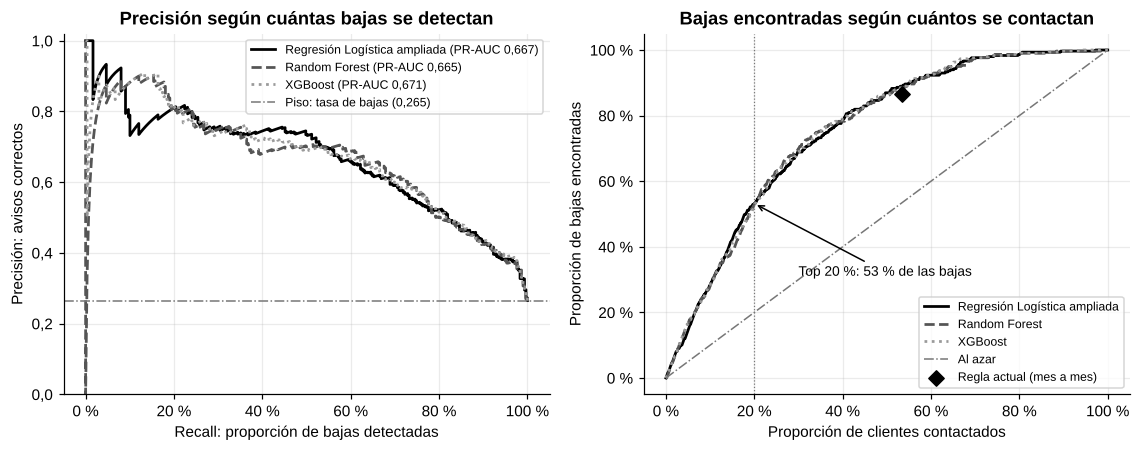

,decil,clientes,bajas,score_min,tasa_baja,captura_acumulada,lift
0,1,112,84,0.637,0.750,0.281,2.827
1,2,113,75,0.510,0.664,0.532,2.502
2,3,113,47,0.381,0.416,0.689,1.568
3,4,112,29,0.268,0.259,0.786,0.976
4,5,113,25,0.192,0.221,0.870,0.834
5,6,113,16,0.118,0.142,0.923,0.534
6,7,112,16,0.062,0.143,0.977,0.538
7,8,113,3,0.027,0.027,0.987,0.100
8,9,113,3,0.010,0.027,0.997,0.100
9,10,113,1,0.002,0.009,1.000,0.033


In [10]:
# Tabla de lift por deciles del modelo elegido
d = pd.DataFrame({'y': y_te, 'p': p_el}).sort_values('p', ascending=False).reset_index(drop=True)
d['decil'] = np.ceil((d.index + 1) / len(d) * 10).astype(int)
lift = d.groupby('decil').agg(clientes=('y', 'size'), bajas=('y', 'sum'), score_min=('p', 'min')).reset_index()
lift['tasa_baja'] = lift.bajas / lift.clientes
lift['captura_acumulada'] = lift.bajas.cumsum() / y_te.sum()
lift['lift'] = lift.tasa_baja / y_te.mean()
guardar(lift, 'lift_deciles.csv')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
cols = {'Regresión Logística ampliada': C_LR, 'Random Forest': C_RF, 'XGBoost': C_XGB}
for nombre, c in cols.items():
    pr, rc, _ = precision_recall_curve(y_te, probas[nombre])
    a1.plot(rc, pr, color=c, ls=LS[nombre], lw=1.8, label=f'{nombre} (PR-AUC {num(average_precision_score(y_te, probas[nombre]))})')
    o = np.argsort(-probas[nombre], kind='stable'); g = np.concatenate([[0], np.cumsum(y_te[o]) / y_te.sum()])
    a2.plot(np.linspace(0, 1, len(g)), g, color=c, ls=LS[nombre], lw=1.8, label=nombre)
a1.axhline(y_te.mean(), color=C_REF, ls='-.', lw=1, label=f'Piso: tasa de bajas ({num(y_te.mean())})')
a1.set_xlabel('Recall: proporción de bajas detectadas'); a1.set_ylabel('Precisión: avisos correctos')
a1.set_title('Precisión según cuántas bajas se detectan'); a1.legend(fontsize=8, loc='upper right'); a1.set_ylim(0, 1.02)
a1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: num(x, 1)))
a2.plot([0, 1], [0, 1], color=C_REF, ls='-.', lw=1, label='Al azar')
a2.scatter([mm_te.mean()], [captura_regla], s=50, color='black', marker='D', zorder=5, label='Regla actual (mes a mes)')
a2.axvline(0.2, color=C_REF, lw=.8, ls=':')
r20 = recall_at_k(y_te, p_el)
a2.annotate(f'Top 20 %: {pct(r20)} de las bajas', (0.2, r20), xytext=(0.3, r20 - 0.22), fontsize=9,
            arrowprops=dict(arrowstyle='->', color='black'))
a2.set_xlabel('Proporción de clientes contactados'); a2.set_ylabel('Proporción de bajas encontradas')
a2.set_title('Bajas encontradas según cuántos se contactan'); a2.legend(fontsize=8, loc='lower right')
for a in (a1, a2):
    a.xaxis.set_major_formatter(FMT_PCT)
a2.yaxis.set_major_formatter(FMT_PCT)
fig.tight_layout(); fig.savefig(f'{RES}/fig_pr_ganancia.png'); plt.show()
lift.round(3)

In [11]:
# Robustez: intervalo bootstrap (1000 remuestreos del holdout) para cada modelo y para la diferencia contra la RL ampliada
rng = np.random.default_rng(SEED)
B, n = 1000, len(y_te)
idx = [rng.integers(0, n, n) for _ in range(B)]
ref = probas['Regresión Logística ampliada']
filas = []
for nombre in ['Regresión Logística base', 'Regresión Logística ampliada', 'Random Forest', 'XGBoost']:
    p = probas[nombre]
    pr_, r20_, dpr, dr20 = [], [], [], []
    for i in idx:
        yy = y_te[i]
        a, b = average_precision_score(yy, p[i]), recall_at_k(yy, p[i])
        pr_.append(a); r20_.append(b)
        dpr.append(a - average_precision_score(yy, ref[i])); dr20.append(b - recall_at_k(yy, ref[i]))
    q = lambda v: np.percentile(v, [2.5, 97.5])
    filas.append({'modelo': nombre, 'pr_auc_ic_inf': q(pr_)[0], 'pr_auc_ic_sup': q(pr_)[1],
                  'recall_top20_ic_inf': q(r20_)[0], 'recall_top20_ic_sup': q(r20_)[1],
                  'dif_pr_auc_vs_RL_inf': q(dpr)[0], 'dif_pr_auc_vs_RL_sup': q(dpr)[1],
                  'dif_recall_top20_vs_RL_inf': q(dr20)[0], 'dif_recall_top20_vs_RL_sup': q(dr20)[1]})
guardar(pd.DataFrame(filas), 'bootstrap_holdout.csv').round(3)

,modelo,pr_auc_ic_inf,pr_auc_ic_sup,recall_top20_ic_inf,recall_top20_ic_sup,dif_pr_auc_vs_RL_inf,dif_pr_auc_vs_RL_sup,dif_recall_top20_vs_RL_inf,dif_recall_top20_vs_RL_sup
0,Regresión Logística base,0.609,0.724,0.487,0.579,-0.004,0.002,-0.010,0.007
1,Regresión Logística ampliada,0.611,0.724,0.489,0.579,0.000,0.000,0.000,0.000
2,Random Forest,0.609,0.724,0.483,0.582,-0.026,0.026,-0.036,0.031
3,XGBoost,0.615,0.728,0.477,0.571,-0.019,0.029,-0.039,0.021


## 6. Interpretación del modelo elegido

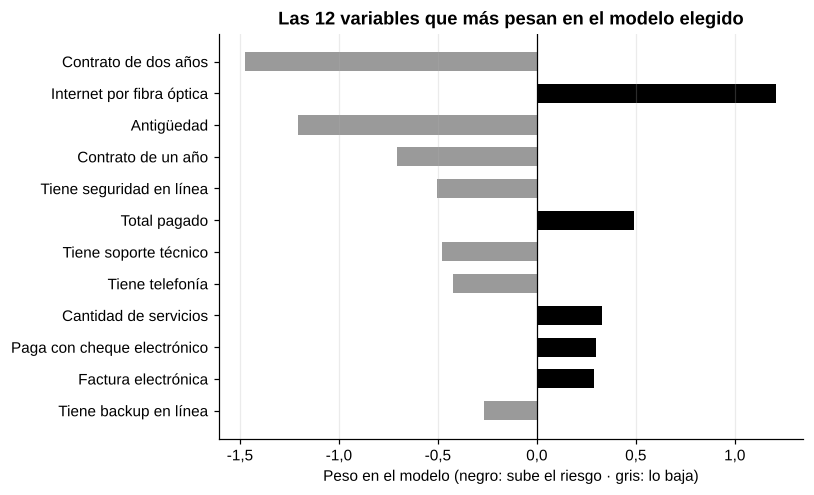

,variable,coeficiente,odds_ratio
0,Contract_Two year,-1.473,0.229
1,InternetService_Fiber optic,1.211,3.355
2,tenure,-1.209,0.299
3,Contract_One year,-0.708,0.492
4,OnlineSecurity_Yes,-0.505,0.604
5,TotalCharges,0.491,1.634
6,TechSupport_Yes,-0.479,0.620
7,PhoneService_Yes,-0.426,0.653
8,n_servicios,0.327,1.386
9,PaymentMethod_Electronic check,0.299,1.349


In [12]:
m = modelos['Regresión Logística ampliada']
nombres = m.named_steps['prep'].get_feature_names_out()
coef = pd.DataFrame({'variable': [n.replace('num__', '').replace('cat__', '') for n in nombres],
                     'coeficiente': m.named_steps['clf'].coef_[0]})
coef['odds_ratio'] = np.exp(coef.coeficiente)
coef = coef.reindex(coef.coeficiente.abs().sort_values(ascending=False).index).reset_index(drop=True)
guardar(coef, 'coeficientes.csv')

NOMBRES = {'Contract_Two year': 'Contrato de dos años', 'Contract_One year': 'Contrato de un año',
           'InternetService_Fiber optic': 'Internet por fibra óptica', 'tenure': 'Antigüedad',
           'OnlineSecurity_Yes': 'Tiene seguridad en línea', 'TotalCharges': 'Total pagado',
           'TechSupport_Yes': 'Tiene soporte técnico', 'PhoneService_Yes': 'Tiene telefonía',
           'n_servicios': 'Cantidad de servicios', 'PaymentMethod_Electronic check': 'Paga con cheque electrónico',
           'PaperlessBilling_Yes': 'Factura electrónica', 'OnlineBackup_Yes': 'Tiene backup en línea',
           'MonthlyCharges': 'Cargo mensual', 'StreamingTV_Yes': 'Tiene TV por streaming',
           'StreamingMovies_Yes': 'Tiene películas por streaming', 'MultipleLines_Yes': 'Tiene varias líneas'}
top = coef.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh([NOMBRES.get(v, v) for v in top.variable], top.coeficiente,
        color=['black' if v > 0 else '#9a9a9a' for v in top.coeficiente], height=.6)
ax.axvline(0, color='black', lw=.8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: num(x, 1)))
ax.set_xlabel('Peso en el modelo (negro: sube el riesgo · gris: lo baja)')
ax.set_title('Las 12 variables que más pesan en el modelo elegido'); ax.grid(axis='y', alpha=0)
fig.tight_layout(); fig.savefig(f'{RES}/fig_coeficientes.png'); plt.show()
coef.head(12).round(3)

Las variables numéricas están estandarizadas, así que su coeficiente indica el efecto de un desvío
estándar. Las categóricas se leen contra la categoría de referencia (por ejemplo, contrato de dos
años contra mes a mes). Los coeficientes describen asociaciones, no causas.

## 7. Consideraciones éticas y auditoría por grupos

El dataset está anonimizado y es público. Igual se revisa si el modelo trata distinto a grupos
sensibles: cuánto de cada grupo entra en el top 20 % y qué tan bien detecta a sus bajas reales.

In [13]:
top20 = np.zeros(len(y_te), dtype=bool); top20[np.argsort(-p_el, kind='stable')[:math.ceil(.2*len(y_te))]] = True
filas = []
for var in ['SeniorCitizen', 'gender', 'Partner', 'Dependents']:
    for cat in sorted(X_te[var].unique()):
        g = (X_te[var] == cat).values
        filas.append({'variable': var, 'grupo': str(cat), 'clientes': int(g.sum()), 'tasa_baja_real': y_te[g].mean(),
                      'pct_en_top20': top20[g].mean(), 'recall_top20_grupo': y_te[g & top20].sum() / max(y_te[g].sum(), 1),
                      'precision_top20_grupo': y_te[g & top20].mean() if (g & top20).any() else np.nan})
audit = guardar(pd.DataFrame(filas), 'auditoria_grupos.csv')

# Ablaciones: sacar variables sensibles o redundantes y medir el costo en el holdout
def evaluar_sin(columnas):
    num = [c for c in NUM_ALL if c not in columnas]; cat = [c for c in CAT if c not in columnas]
    mm_ = Pipeline([('prep', preproc(num, cat, True)), ('clf', LogisticRegression(max_iter=2000, random_state=SEED))])
    mm_.fit(X_tr[num + cat], y_tr); p = mm_.predict_proba(X_te[num + cat])[:, 1]
    return {'roc_auc': roc_auc_score(y_te, p), 'pr_auc': average_precision_score(y_te, p), 'recall_top20': recall_at_k(y_te, p)}
abl = []
for etiqueta, cols_ in [('Modelo completo', []), ('Sin gender', ['gender']), ('Sin SeniorCitizen', ['SeniorCitizen']),
                        ('Sin gender ni SeniorCitizen', ['gender', 'SeniorCitizen']), ('Sin TotalCharges', ['TotalCharges']),
                        ('Sin variables nuevas', NUM_NUEVAS)]:
    abl.append({'configuracion': etiqueta, **evaluar_sin(cols_)})
abl = guardar(pd.DataFrame(abl), 'ablaciones.csv')
display(audit.round(3)); abl.round(4)

,variable,grupo,clientes,tasa_baja_real,pct_en_top20,recall_top20_grupo,precision_top20_grupo
0,SeniorCitizen,0,936,0.234,0.162,0.484,0.697
1,SeniorCitizen,1,191,0.419,0.387,0.662,0.716
2,gender,Female,565,0.255,0.228,0.618,0.690
3,gender,Male,562,0.276,0.173,0.452,0.722
4,Partner,No,574,0.314,0.265,0.583,0.691
5,Partner,Yes,553,0.215,0.134,0.454,0.730
6,Dependents,No,799,0.302,0.249,0.581,0.704
7,Dependents,Yes,328,0.177,0.082,0.328,0.704


,configuracion,roc_auc,pr_auc,recall_top20
0,Modelo completo,0.8482,0.6673,0.5318
1,Sin gender,0.8485,0.6666,0.5284
2,Sin SeniorCitizen,0.8479,0.6645,0.5385
3,Sin gender ni SeniorCitizen,0.8482,0.6651,0.5385
4,Sin TotalCharges,0.8464,0.6647,0.5351
5,Sin variables nuevas,0.8482,0.6665,0.5318


## 8. Impacto en el negocio: escenarios

**Importante.** Estos datos no permiten medir cuánto ingreso se retiene ni cuánto baja el churn
después de contactar: para eso hace falta una campaña con grupo de control. Lo que sigue es un
cálculo de escenarios con supuestos explícitos, sobre los 1.127 clientes del holdout.

- Valor en riesgo de una baja: 12 meses de su cargo mensual real.
- Costo de contacto: 15 USD (supuesto) y 30 USD (sensibilidad).
- Aceptación de la oferta entre quienes se iban a ir: 10 %, 20 % o 30 % (supuestos).
- Beneficio neto = aceptación × valor en riesgo de las bajas contactadas − costo × clientes contactados.

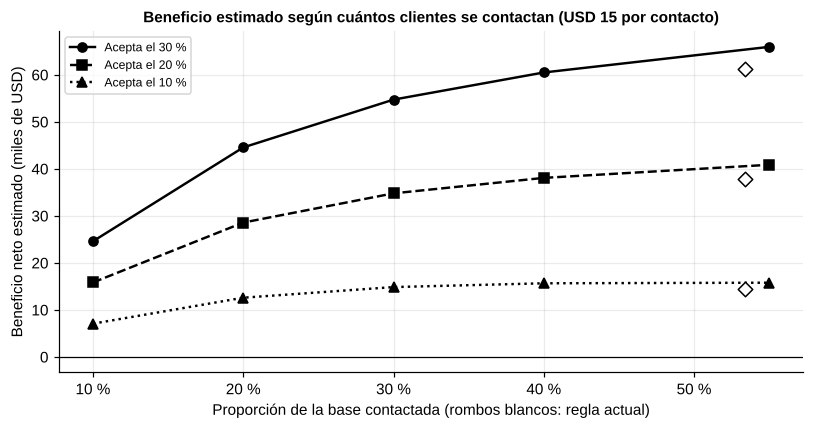

aceptacion,0.1,0.2,0.3
estrategia,,,
Modelo top 10%,7065.0,15825.0,24584.0
Modelo top 20%,12586.0,28563.0,44539.0
Modelo top 30%,14846.0,34777.0,54708.0
Modelo top 40%,15650.0,38066.0,60481.0
Modelo top 55%,15775.0,40851.0,65926.0
Regla actual (mes a mes),14421.0,37871.0,61322.0


In [14]:
val12 = (X_te.MonthlyCharges.values * 12)
orden = np.argsort(-p_el, kind='stable')
filas = []
for frac in [0.10, 0.20, 0.30, 0.40, 0.55]:
    k = math.ceil(frac * len(y_te)); sel = orden[:k]
    v_tp = (val12[sel] * y_te[sel]).sum()
    for costo in [15, 30]:
        for acept in [0.10, 0.20, 0.30]:
            filas.append({'estrategia': f'Modelo top {frac:.0%}', 'pct_contactado': frac, 'contactados': k, 'bajas_contactadas': int(y_te[sel].sum()),
                          'valor_riesgo_contactado': v_tp, 'costo_contacto': costo, 'aceptacion': acept,
                          'beneficio_neto': acept * v_tp - costo * k, 'aceptacion_equilibrio': costo * k / v_tp})
sel = np.where(mm_te == 1)[0]; v_tp = (val12[sel] * y_te[sel]).sum()
for costo in [15, 30]:
    for acept in [0.10, 0.20, 0.30]:
        filas.append({'estrategia': 'Regla actual (mes a mes)', 'pct_contactado': mm_te.mean(), 'contactados': len(sel),
                      'bajas_contactadas': int(y_te[sel].sum()), 'valor_riesgo_contactado': v_tp, 'costo_contacto': costo,
                      'aceptacion': acept, 'beneficio_neto': acept * v_tp - costo * len(sel), 'aceptacion_equilibrio': costo * len(sel) / v_tp})
esc = guardar(pd.DataFrame(filas), 'escenario_economico.csv')

base = esc[esc.costo_contacto == 15]
fig, ax = plt.subplots(figsize=(7.5, 4))
for acept, ls, mk in zip([0.30, 0.20, 0.10], ['-', '--', ':'], ['o', 's', '^']):
    s = base[(base.aceptacion == acept) & base.estrategia.str.startswith('Modelo')]
    ax.plot(s.pct_contactado, s.beneficio_neto / 1000, color='black', ls=ls, marker=mk, lw=1.6, label=f'Acepta el {pct(acept)}')
    r = base[(base.aceptacion == acept) & (base.estrategia == 'Regla actual (mes a mes)')]
    ax.scatter(r.pct_contactado, r.beneficio_neto / 1000, marker='D', s=45, facecolor='white', edgecolor='black', zorder=5)
ax.axhline(0, color='black', lw=.8)
ax.set_xlabel('Proporción de la base contactada (rombos blancos: regla actual)'); ax.set_ylabel('Beneficio neto estimado (miles de USD)')
ax.set_title('Beneficio estimado según cuántos clientes se contactan (USD 15 por contacto)', fontsize=10)
ax.xaxis.set_major_formatter(FMT_PCT); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f'{RES}/fig_escenarios.png'); plt.show()
esc[(esc.costo_contacto == 15)].pivot_table(index='estrategia', columns='aceptacion', values='beneficio_neto', sort=False).round(0)

## 9. Scoring del archivo de prueba

Se reentrena el modelo elegido con todo `train.csv` y se puntúa `test.csv` (sin etiquetas). La
salida es la lista ordenada que usaría Retención.

In [15]:
final = modelos[ELEGIDO]
final.fit(X, y)
Xt = preparar(test).drop(columns=['customerID'])
pt = final.predict_proba(Xt)[:, 1]
pred = pd.DataFrame({'customerID': test.customerID, 'prob_baja': pt})
pred['ranking'] = pred.prob_baja.rank(ascending=False, method='first').astype(int)
pred['top20'] = pred.ranking <= math.ceil(.2 * len(pred))
guardar(pred.sort_values('ranking'), 'predicciones_test.csv').head(10)

,customerID,prob_baja,ranking,top20
1090,5178-LMXOP,0.854857,1,True
1221,0295-PPHDO,0.832201,2,True
1175,6861-XWTWQ,0.825181,3,True
889,2545-EBUPK,0.824305,4,True
647,6023-YEBUP,0.823902,5,True
1164,8884-ADFVN,0.820209,6,True
1138,1400-MMYXY,0.820196,7,True
1109,1069-XAIEM,0.819188,8,True
627,9057-SIHCH,0.818143,9,True
995,8161-QYMTT,0.816152,10,True


## 10. Conclusiones

- **Modelo elegido: Regresión Logística ampliada.** XGBoost lidera la validación cruzada por
  menos de un desvío entre folds (PR-AUC 0,667 contra 0,659) y en el holdout los intervalos
  bootstrap de la diferencia incluyen el cero. Según la regla fijada de antemano se elige el modelo
  más simple, que además es interpretable para Retención.
- **Lo que el modelo sí demuestra.** Con capacidad para contactar al 20 % de la base, el top 20 %
  concentra el 53 % de las bajas reales, con 70 % de avisos correctos: 2,7 veces más que al azar
  y bastante más que elegir mes a mes sin orden (alrededor de 32 %). Ponderar las clases no
  cambió el orden de los clientes.
- **Lo que no demuestra.** Cuánto ingreso se conserva o cuánto baja el churn al contactar: los
  escenarios de la sección 8 dependen de supuestos de costo y aceptación. El paso siguiente es un
  piloto con grupo de control.
- **Ética.** Las ablaciones muestran que `gender` no aporta capacidad predictiva; se recomienda
  sacarla del modelo productivo. Los mayores de 65 aparecen más en el top 20 % porque se dan más
  de baja; la acción de retención debe ser una oferta, nunca una penalización.